# 01. Sequential Multimodal Narrative Generator

This notebook demonstrates a complete, sequential multimodal-to-text pipeline using state-of-the-art LLMs. We leverage **DeepSeek's vision model** to extract highly structured metadata from a collection of images and **Google's Gemma model** to synthesize those details into a creative, cinematic sci-fi narrative.

### Repository
This work is part of the experimental projects hosted at: [ShivaUlavi/GenAI/MultiModalAgents](https://github.com/ShivaUlavi/GenAI/tree/main/MultiModalAgents)

---

## 1. Setup & API Initialization
We start by retrieving credentials and configuring the models using LangChain adapters.

In [ ]:
import os
api_key = os.getenv("AICREDITS_API_KEY")
base_url = os.getenv("AICREDITS_BASE_URL")

### Model Configuration
We initialize two different models for our tasks:
*   **DeepSeek (`deepseek-v4-flash-vision-exp`)**: Dedicated to vision and structured metadata extraction.
*   **Gemma (`google/gemma-4-31b-it`)**: Dedicated to creative writing and synthesis.

In [ ]:
from langchain_openai import ChatOpenAI

os.environ["OPENAI_API_KEY"] = api_key
os.environ["OPENAI_BASE_URL"] = base_url

llm = ChatOpenAI(model= "google/gemma-4-31b-it")
llm2= ChatOpenAI(model="deepseek/deepseek-v4-flash-vision-exp")

## 2. Preliminary Vision Testing
Before processing in batches, we run a quick sanity check to verify that our image encoding and LLM vision capabilities are working properly on a single sample image.

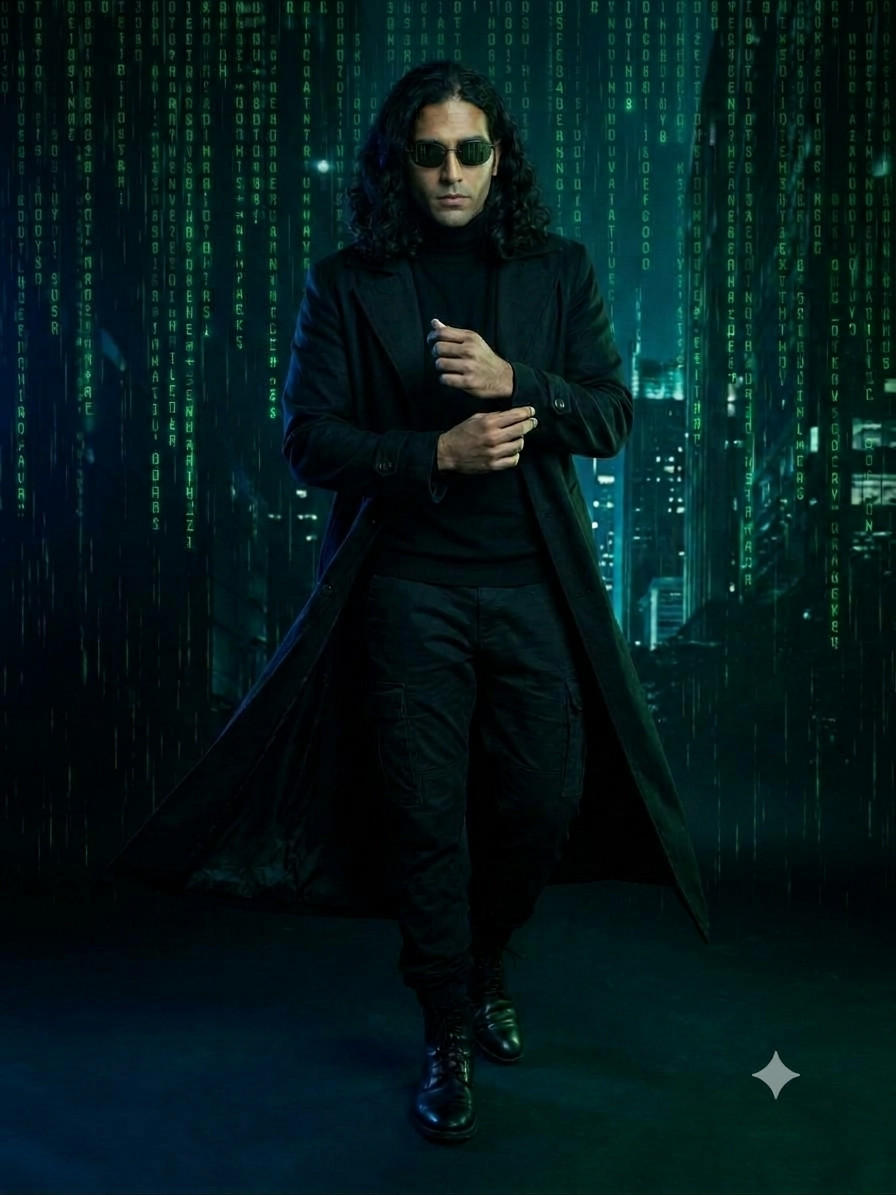

In [ ]:
from IPython.display import Image, display

# Pass the absolute file path to filename
display(Image(filename="C:/Users/Shivachetan Ulavi/Downloads/Gemini_Generated_Image_nc5si4nc5si4nc5s.png"))

### Generate Base64 Payload
For LLMs to consume images via API, we encode the image to a Base64 string payload.

In [ ]:
from langchain_core.messages import HumanMessage
import base64

with open("C:/Users/Shivachetan Ulavi/Downloads/Gemini_Generated_Image_nc5si4nc5si4nc5s.png", "rb") as img_file:
    image_bytes = img_file.read()
    base64_bytes = base64.b64encode(image_bytes).decode("utf-8")

print("Base64 string generated successfully!")

Base64 string generated successfully!


### Run Comparative Visual Analysis
Let's evaluate the descriptive capabilities of both `google/gemma-4-31b-it` and `deepseek-v4-flash-vision-exp`.

In [ ]:
prompt = [

    {"type": "text", "text" : "describe the image: "},
    {"type": "image_url", "image_url" :{"url": f"data:image/png;base64,{base64_bytes}"}},
]

response = llm.invoke([HumanMessage(content=prompt)])
print(response.content)


A full-length studio portrait of a man dressed in a style reminiscent of the movie *The Matrix*. 

The man has long, curly dark hair and is wearing dark sunglasses. His attire consists of a long black overcoat worn over a black turtleneck sweater, black cargo pants, and black leather boots. He is posed facing forward, with one hand slightly raised toward his chest, giving him a serious and composed expression.

The background is a dark, atmospheric scene featuring the iconic "digital rain" effect—cascading vertical lines of glowing green alphanumeric characters and symbols. Behind the digital rain, there are faint outlines of a futuristic, dark cityscape with tall buildings. The overall lighting is moody and low-key, with a strong green tint that emphasizes the cyberpunk aesthetic.


In [ ]:
response2 = llm2.invoke([HumanMessage(content=prompt)])
print(response2.content)


The image is a cinematic, sci-fi-themed portrait heavily inspired by the aesthetic of *The Matrix*. 

**The Subject:**
In the center is a man walking forward with a purposeful stride. He has shoulder-length, dark, wavy hair and is wearing dark, rectangular sunglasses. His outfit consists of a long, flowing black trench coat worn open over a black turtleneck sweater, paired with dark tactical or cargo pants and black leather dress shoes. His hands are clasped together in front of his chest in a composed, deliberate pose.

**The Background:**
The background features the iconic "digital rain" effect—falling streams of glowing neon green characters (letters, numbers, and symbols) on a dark canvas. Behind the falling code, there is a blurred, moody depiction of a futuristic cityscape with faint, vertical lights suggesting skyscrapers at night.

**Lighting and Style:**
The color palette is dominated by deep blacks, dark teals, and vibrant, glowing greens. The lighting highlights the man's fa

## 3. Batch Image Processing pipeline & Structured Extraction
Now we will prepare a complete set of local test images, process them dynamically, resize/compress them to fit LLM constraints safely, and extract metadata using Pydantic structured schemas.

### Structured Data Extraction with clothing and lighting

In [ ]:
import mimetypes
import base64
from pathlib import Path
from pydantic import BaseModel, Field
from langchain_core.messages import HumanMessage

#Defining the Schema
class ImageMetadata(BaseModel):
    subject_type: str = Field(description="Type of subject, e.g., 'human portrait', 'dog', 'group'")
    dominant_colors: str = Field(description="Top 3 dominant colors in the image")
    setting_or_background: str = Field(description="The environment or background setting")
    expression_or_pose: str = Field(description="Facial expression, posture, or pose of the subject")
    clothing_details: str = Field(description="Description of the subjects' clothing, attire, fabric, or styling")
    lighting_parameters: str = Field(description="Details on photography lighting, mood, or environment lighting")
    detailed_summary: str = Field(description="A concise summary of what is depicted in the image")

structured_llm = llm2.with_structured_output(ImageMetadata)

### Locating Target Images
We read from the local desktop directory and filter for standard image files.

In [ ]:
image_dir = Path("C:/Users/Shivachetan Ulavi/Desktop/TestImages/")
supported_extns = {".jpeg", ".png", ".jpg", ".webp"}
image_paths = [p for p in image_dir.iterdir() if p.suffix.lower() in supported_extns]
image_paths

[WindowsPath('C:/Users/Shivachetan Ulavi/Desktop/TestImages/Gemini_Generated_Image_glon0cglon0cglon.png'),
 WindowsPath('C:/Users/Shivachetan Ulavi/Desktop/TestImages/Gemini_Generated_Image_nc5si4nc5si4nc5s.png'),
 WindowsPath('C:/Users/Shivachetan Ulavi/Desktop/TestImages/IMG20181221104311.jpg'),
 WindowsPath('C:/Users/Shivachetan Ulavi/Desktop/TestImages/IMG_1967.jpg'),
 WindowsPath('C:/Users/Shivachetan Ulavi/Desktop/TestImages/Shiva Fitness Edits-39.jpg')]

### Image Optimization Utility
To ensure API calls do not fail due to size limits, we implement an auto-resizing and JPEG-compression helper.

In [ ]:
import base64
from pathlib import Path
import mimetypes
from PIL import Image
import io

def encode_and_resize_image(image_path: Path, max_size=(1024, 1024), quality=85):
    """
    Opens an image, resizes it if it's too large, compresses it,
    and returns the base64 string and MIME type.
    """
    with Image.open(image_path) as img:
        # Convert transparent formats (like PNG RGBA) to RGB for safe compression
        if img.mode in ("RGBA", "P"):
            img = img.convert("RGB")

        # Resize image maintaining aspect ratio so it fits within max_size (e.g., 1024x1024)
        img.thumbnail(max_size)

        # Save the compressed image into an in-memory byte buffer
        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=quality)

        # Encode bytes to base64 string
        encoded_string = base64.b64encode(buffer.getvalue()).decode('utf-8')

    return encoded_string, "image/jpeg"

### Visualizing the Batch
Let's plot all discovered images alongside each other to inspect our dynamic dataset.

The Images for your context

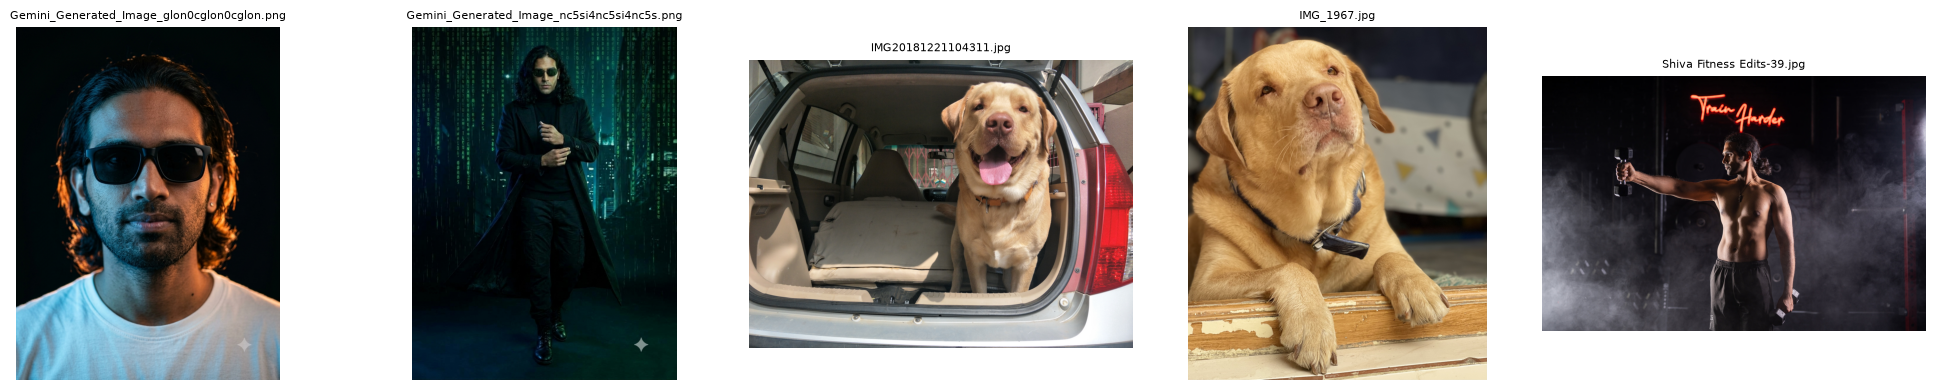

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, len(image_paths), figsize=(4 * len(image_paths), 4))

if len(image_paths)==1:
    axes = [axes]

for ax, path in zip(axes, image_paths):
    img = Image.open(path)
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(path.name, fontsize = 8)

plt.tight_layout()
plt.show()

### Executing Structured Extractions
We pass each optimized image to DeepSeek using LangChain's structured output mechanism to guarantee valid JSON adhering to our Pydantic model.

In [ ]:
extracted_metadata = []

for idx, path in enumerate(image_paths):
    # This automatically resizes and compresses large files under 5MB
    base64_img, mime_type = encode_and_resize_image(path)

    message = HumanMessage(content=[
        {"type": "text", "text": "Analyze this image and extract the structured metadata, paying close attention to wardrobe style and lighting conditions."},
        {
            "type": "image_url",
            "image_url": {"url": f"data:{mime_type};base64,{base64_img}"}
        }
    ])

    result = structured_llm.invoke([message])
    extracted_metadata.append(result)
    print(f"--- Processed {path.name} ({mime_type}) ---")
    print(result.model_dump_json(indent=2))

--- Processed Gemini_Generated_Image_glon0cglon0cglon.png (image/jpeg) ---
{
  "subject_type": "Adult male portrait",
  "dominant_colors": "Black (background), White (shirt), Cyan (light), Orange/Amber (light)",
  "setting_or_background": "Solid black/very dark, studio backdrop",
  "expression_or_pose": "Neutral, direct frontal gaze, head and shoulders framing",
  "clothing_details": "Plain white crew-neck t-shirt, standard relaxed fit, subtle stitch detailing on the collar, small white diamond/sparkle logo on the bottom right (viewer's right) chest. No visible necklaces or other jewelry on the torso. The subject is also wearing large black wayfarer-style sunglasses with opaque lenses, which serve as a primary fashion statement.",
  "lighting_parameters": "Cinematic bi-color split lighting. A warm orange/amber light source illuminates the right side (viewer's right) of the subject's face, hair, and shoulder. A cool cyan/blue light source illuminates the left side (viewer's left). This 

## 4. Synthesis & Creative Story Generation
In this final step, we feed all the extracted structured metadata blocks into the Gemma model. Our carefully crafted system prompt instructs the model to build an integrated, cinematic sci-fi script incorporating all visual cues.

### sequential multimodal to text pipeline

In [ ]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

narrative_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "You are an expert sci-fi action thriller novelist and screenwriter. "
        "Your task is to write an edge-of-your-seat, cinematic science-fiction action plot "
        "where the protagonist (Shiva) and his loyal, highly-trained canine partner are co-protagonists.\n\n"
        "Guidelines:\n"
        "1. Incorporate visual cues from the structured image metadata (such as the futuristic cyberpunk setting, "
        "the tactical trench coat attire, intense training sessions, split-tone studio lighting, and getaway vehicle moments).\n"
        "2. Blend futuristic sci-fi tech concepts (e.g., cybernetics, digital matrix networks, tactical intelligence) "
        "with high-stakes physical action and tactical operations.\n"
        "3. Frame the dog not just as a pet, but as an indispensable tactical partner with incredible instincts and high intelligence.\n"
        "4. Deliver a thrilling, fast-paced narrative that flows seamlessly across all scenes."
    ),
    ("user", "Here is the structured metadata extracted from our photo session:\n\n{metadata_list}")
])

### Defining the Narrative Chain
We construct a sequential chain using LangChain Expression Language (LCEL) to stitch the list of metadata objects together and feed them directly into the novelist engine.

In [ ]:
chain = (
    {
        "metadata_list": lambda inputs: "\n\n".join(
            [f"Photo {i+1} Details:\n{meta.model_dump_json(indent=2)}" for i, meta in enumerate(inputs)]
        )
    }
    | narrative_prompt
    | llm
    | StrOutputParser()
)

final_story = chain.invoke(extracted_metadata)

print("--- Generated Multimodal Narrative ---")
print(final_story)


--- Generated Multimodal Narrative ---
# TITLE: NEURAL BOND: THE GHOST PROTOCOL

## THE PROLOGUE: THE DUALITY OF MAN
The screen opens on a stark, void-black expanse. **SHIVA** stands center-frame. The lighting is a violent split: a cold, surgical **Cyan** on his left, a burning **Amber** on his right. He wears a simple white tee and opaque black wayfarers, his expression a mask of stoic intensity. This is the "Calibration Phase." Shiva isn't just a man; he is the world’s first successful "Bi-Link" operative—his consciousness bridged with a tactical AI.

But the AI isn't in a computer. It’s in **KAI**, a golden Labrador Retriever with a cognitive enhancer embedded in his neural cortex.

## ACT I: THE GHOST IN THE MACHINE
The scene shifts abruptly to the neon-drenched sprawl of *Neo-Kashi*. The air is thick with digital rain—cascades of green code falling through the skyscrapers. Shiva is now in his operational gear: a sweeping black tactical trench coat, a high-neck turtleneck, and comb

## Conclusion
We successfully demonstrated a multi-model cooperative agent workflow where:
1. **DeepSeek** handled structured visual perception.
2. **Gemma** synthesized descriptions into a cinematic screenplay.
